# LSTM tự cài đặt bằng NumPy (không dùng PyTorch / Keras)

**Nhóm 5:** Nguyễn Phú Đại · Trần Vũ Tiến Minh · Trần Đình Hiếu · Phạm Thanh An

Notebook này trả lời hai góp ý của thầy:

1. **Cấu trúc code của LSTM** được viết như một **hợp của các hàm sơ cấp** (*elementary functions*): nhân ma trận cộng độ lệch, sigmoid, tanh, nhân từng phần tử, cộng. Mỗi hàm sơ cấp có hai nửa: tính xuôi (*forward*) và tính đạo hàm ngược (*backward*). Lan truyền ngược của cả ô LSTM chỉ là gọi lại các nửa ngược đó theo thứ tự đảo. Toàn bộ chỉ dùng NumPy.
2. **Slide 18 phải dựa trên một mô hình thật**, có số lớp và số nơ-ron cụ thể. Bản cũ của slide 18 chỉ vẽ hai hàm mũ $0.9^k$ và $0.99^k$, không có mạng nào cả. Ở đây nhóm huấn luyện thật một RNN và một LSTM viết bằng NumPy (cùng cấu hình thí nghiệm 3) rồi **đo** tín hiệu lỗi đi ngược về từng bước.

**Kiến trúc** (giống thí nghiệm 3, `lstm_adding.ipynb`): đầu vào 2 số mỗi bước → **1 lớp** LSTM (hoặc RNN) với **64 nơ-ron ẩn** → lấy trạng thái ẩn ở bước cuối → **1 nơ-ron** đầu ra tuyến tính.

Kết quả cho slide ghi vào `slides/data/numpy_lstm.json`, hình lưu vào `experiment/figures/`.

In [1]:
import json, time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

SLIDES_DATA, RESULTS, FIGURES = Path('..') / 'slides' / 'data', Path('results'), Path('figures')
for p in (SLIDES_DATA, RESULTS, FIGURES):
    p.mkdir(parents=True, exist_ok=True)
plt.rcParams['figure.dpi'] = 100
print('numpy', np.__version__)

numpy 2.4.6


## 1. Các hàm sơ cấp

Mỗi hàm trả về `(kết quả, cache)`; hàm `*_back(d, cache)` nhận đạo hàm của hàm mất mát theo kết quả và trả về đạo hàm theo các đầu vào (quy tắc dây chuyền cho đúng một phép toán).

| Hàm | Xuôi | Ngược |
|---|---|---|
| `affine(x, W, b)` | $xW + b$ | $dx = d\,W^\top,\ dW = x^\top d,\ db = \sum d$ |
| `sigmoid(z)` | $\sigma(z) = 1/(1+e^{-z})$ | $d \cdot \sigma(1-\sigma)$ |
| `tanh(z)` | $\tanh z$ | $d \cdot (1-\tanh^2 z)$ |
| `mul(a, b)` | $a \odot b$ | $da = d \odot b,\ db = d \odot a$ |
| `add(a, b)` | $a + b$ | $da = d,\ db = d$ |

In [2]:
def affine(x, W, b):  return x @ W + b, (x, W)
def affine_back(d, cache):
    x, W = cache
    return d @ W.T, x.T @ d, d.sum(0)

def sigmoid(z):
    s = 1 / (1 + np.exp(-z))
    return s, s
def sigmoid_back(d, s): return d * s * (1 - s)

def tanh(z):
    t = np.tanh(z)
    return t, t
def tanh_back(d, t): return d * (1 - t * t)

def mul(a, b):        return a * b, (a, b)
def mul_back(d, cache):
    a, b = cache
    return d * b, d * a

def add(a, b):        return a + b, None
def add_back(d, _):   return d, d

## 2. Một ô LSTM = hợp của các hàm sơ cấp

Ở mỗi bước, ghép đầu vào $x_t$ với đầu ra bước trước $h_{t-1}$ rồi qua **một** phép `affine` chung cho cả 4 phần (4 bộ trọng số đặt cạnh nhau thành ma trận $(D+H) \times 4H$). Thứ tự 4 phần giống PyTorch: cổng ghi $i$, cổng quên $f$, nội dung mới $g$, cổng đọc $o$.

$$
\begin{aligned}
z &= \text{affine}([x_t, h_{t-1}], W, b) \\
i = \sigma(z_i),\quad f &= \sigma(z_f),\quad g = \tanh(z_g),\quad o = \sigma(z_o) \\
c_t &= \text{add}(\text{mul}(f, c_{t-1}),\ \text{mul}(i, g)) \\
h_t &= \text{mul}(o, \tanh(c_t))
\end{aligned}
$$

Hàm `lstm_cell_back` đi ngược đúng các dòng trên, từ dưới lên, mỗi dòng gọi nửa ngược của hàm sơ cấp tương ứng. Chú ý dòng `dc_prev = df_c ⊙ f`: đạo hàm theo bộ nhớ cũ **chỉ nhân với cổng quên**, đây chính là "con đường thẳng" của slide 17.

In [3]:
def lstm_cell(x, h_prev, c_prev, W, b):
    H = h_prev.shape[1]
    z, k_z = affine(np.concatenate([x, h_prev], axis=1), W, b)
    i, k_i = sigmoid(z[:, 0*H:1*H])        # cổng ghi
    f, k_f = sigmoid(z[:, 1*H:2*H])        # cổng quên
    g, k_g = tanh(z[:, 2*H:3*H])           # nội dung mới
    o, k_o = sigmoid(z[:, 3*H:4*H])        # cổng đọc
    fc, k_fc = mul(f, c_prev)              # giữ lại bao nhiêu bộ nhớ cũ
    ig, k_ig = mul(i, g)                   # ghi thêm bao nhiêu nội dung mới
    c, _ = add(fc, ig)                     # bộ nhớ mới
    tc, k_tc = tanh(c)
    h, k_h = mul(o, tc)                    # đầu ra
    return h, c, (k_z, k_i, k_f, k_g, k_o, k_fc, k_ig, k_tc, k_h)


def lstm_cell_back(dh, dc, cache):
    k_z, k_i, k_f, k_g, k_o, k_fc, k_ig, k_tc, k_h = cache
    do, dtc = mul_back(dh, k_h)
    dc = dc + tanh_back(dtc, k_tc)         # bộ nhớ nhận lỗi từ 2 phía: bước sau và đầu ra
    dfc, dig = add_back(dc, None)
    df, dc_prev = mul_back(dfc, k_fc)      # dc_prev = dfc * f : chỉ nhân với cổng quên
    di, dg = mul_back(dig, k_ig)
    dz = np.concatenate([sigmoid_back(di, k_i), sigmoid_back(df, k_f),
                         tanh_back(dg, k_g), sigmoid_back(do, k_o)], axis=1)
    dxh, dW, db = affine_back(dz, k_z)
    H = dh.shape[1]
    return dxh[:, :-H], dxh[:, -H:], dc_prev, dW, db     # dx, dh_prev, dc_prev, dW, db

## 3. Cả mạng: lặp ô LSTM theo thời gian + 1 nơ-ron đầu ra

- **Xuôi:** gọi `lstm_cell` lần lượt từ bước 1 đến $T$, giữ cache của từng bước.
- **Ngược (BPTT, lan truyền ngược theo thời gian):** gọi `lstm_cell_back` từ bước $T$ về bước 1, cộng dồn đạo hàm của $W, b$ (dùng chung ở mọi bước). Lưu thêm $\partial \hat y / \partial x_t$ để đo ở mục 6.
- Để so sánh, RNN được viết cùng kiểu: mỗi bước chỉ có `affine` rồi `tanh`.

Khởi tạo giống PyTorch: mọi trọng số $\sim U(-1/\sqrt{H}, 1/\sqrt{H})$. Riêng LSTM đặt độ lệch cổng quên bằng 1 (mẹo 1 của slide 24).

**Số tham số:** LSTM $(2 + 64)\cdot 256 + 256 + 64 + 1 = 17\,217$; RNN $(2+64)\cdot 64 + 64 + 64 + 1 = 4\,353$. (PyTorch có 2 vector độ lệch cho mỗi lớp nên ra 17 473 và 4 417; về toán học hai cách là một.)

In [4]:
class LSTMNumpy:
    def __init__(self, D, H, seed=0, forget_bias=1.0):
        rng, k = np.random.default_rng(seed), 1 / np.sqrt(H)
        self.H = H
        self.p = {'W': rng.uniform(-k, k, (D + H, 4 * H)), 'b': rng.uniform(-k, k, 4 * H),
                  'V': rng.uniform(-k, k, (H, 1)),         'c': rng.uniform(-k, k, 1)}
        self.p['b'][H:2 * H] = forget_bias

    def forward(self, X):                                   # X: (B, T, D) -> (B, 1)
        B, T, _ = X.shape
        h, c = np.zeros((B, self.H)), np.zeros((B, self.H))
        self.caches = []
        for t in range(T):
            h, c, k = lstm_cell(X[:, t], h, c, self.p['W'], self.p['b'])
            self.caches.append(k)
        y, self.k_out = affine(h, self.p['V'], self.p['c'])
        return y

    def backward(self, dy):                                 # dy = dL/dy_hat
        g = {k: np.zeros_like(v) for k, v in self.p.items()}
        dh, g['V'], g['c'] = affine_back(dy, self.k_out)
        dc, dxs = np.zeros_like(dh), []
        for k in reversed(self.caches):
            dx, dh, dc, dW, db = lstm_cell_back(dh, dc, k)
            g['W'] += dW; g['b'] += db; dxs.append(dx)
        self.dX = np.stack(dxs[::-1], axis=1)               # dL/dx_t cho từng bước
        return g

    def forget_gates(self):                                 # giá trị cổng quên ở từng bước: (B, T, H)
        return np.stack([k[2] for k in self.caches], axis=1)

    def n_params(self): return sum(v.size for v in self.p.values())


class RNNNumpy:
    def __init__(self, D, H, seed=0):
        rng, k = np.random.default_rng(seed), 1 / np.sqrt(H)
        self.H = H
        self.p = {'W': rng.uniform(-k, k, (D + H, H)), 'b': rng.uniform(-k, k, H),
                  'V': rng.uniform(-k, k, (H, 1)),     'c': rng.uniform(-k, k, 1)}

    def forward(self, X):
        B, T, _ = X.shape
        h = np.zeros((B, self.H))
        self.caches = []
        for t in range(T):
            z, k_z = affine(np.concatenate([X[:, t], h], axis=1), self.p['W'], self.p['b'])
            h, k_h = tanh(z)
            self.caches.append((k_z, k_h))
        y, self.k_out = affine(h, self.p['V'], self.p['c'])
        return y

    def backward(self, dy):
        g = {k: np.zeros_like(v) for k, v in self.p.items()}
        dh, g['V'], g['c'] = affine_back(dy, self.k_out)
        dxs = []
        for k_z, k_h in reversed(self.caches):
            dxh, dW, db = affine_back(tanh_back(dh, k_h), k_z)   # mỗi bước: qua tanh rồi qua W
            g['W'] += dW; g['b'] += db
            dxs.append(dxh[:, :-self.H]); dh = dxh[:, -self.H:]
        self.dX = np.stack(dxs[::-1], axis=1)
        return g

    def n_params(self): return sum(v.size for v in self.p.values())


print('Số tham số  LSTM:', LSTMNumpy(2, 64).n_params(), '| RNN:', RNNNumpy(2, 64).n_params())

Số tham số  LSTM: 17217 | RNN: 4353


## 4. Kiểm tra lan truyền ngược

**(a) Sai phân hữu hạn:** so đạo hàm giải tích với $\frac{L(\theta+\epsilon) - L(\theta-\epsilon)}{2\epsilon}$ trên một mạng nhỏ. Sai số tương đối khoảng $10^{-7}$ trở xuống nghĩa là phần ngược viết đúng.

In [5]:
def mse(y_hat, y):
    return ((y_hat - y) ** 2).mean(), 2 * (y_hat - y) / y.size

def grad_check(model, X, y, eps=1e-6):
    loss, dy = mse(model.forward(X), y)
    grads = model.backward(dy)
    for name, P in model.p.items():
        num = np.zeros_like(P)
        for idx in np.ndindex(P.shape):
            old = P[idx]
            P[idx] = old + eps; lp, _ = mse(model.forward(X), y)
            P[idx] = old - eps; lm, _ = mse(model.forward(X), y)
            P[idx] = old;       num[idx] = (lp - lm) / (2 * eps)
        rel = np.linalg.norm(num - grads[name]) / (np.linalg.norm(num) + np.linalg.norm(grads[name]))
        print(f'  {name}: sai số tương đối = {rel:.1e}')

rng = np.random.default_rng(0)
Xc, yc = rng.standard_normal((4, 7, 2)), rng.standard_normal((4, 1))
print('LSTM'); grad_check(LSTMNumpy(2, 5, seed=1), Xc, yc)
print('RNN');  grad_check(RNNNumpy(2, 5, seed=1), Xc, yc)

LSTM
  W: sai số tương đối = 1.5e-09
  b: sai số tương đối = 7.4e-10
  V: sai số tương đối = 2.7e-10
  c: sai số tương đối = 1.5e-10
RNN
  W: sai số tương đối = 2.7e-10
  b: sai số tương đối = 4.6e-10
  V: sai số tương đối = 6.7e-11
  c: sai số tương đối = 5.1e-11


**(b) Đối chiếu với PyTorch** (chỉ để kiểm tra, mô hình không dùng PyTorch ở bất kỳ chỗ nào khác): chép trọng số NumPy vào `nn.LSTM`, so đầu ra và đạo hàm. Ô này bỏ qua nếu máy không có PyTorch.

In [6]:
try:
    import torch
    m = LSTMNumpy(2, 5, seed=3)
    W, b, H = m.p['W'], m.p['b'], 5
    t_lstm = torch.nn.LSTM(2, H, batch_first=True).double()
    with torch.no_grad():
        t_lstm.weight_ih_l0.copy_(torch.tensor(W[:2].T)); t_lstm.weight_hh_l0.copy_(torch.tensor(W[2:].T))
        t_lstm.bias_ih_l0.copy_(torch.tensor(b));         t_lstm.bias_hh_l0.zero_()
    Xt = torch.tensor(Xc, requires_grad=True)
    out, _ = t_lstm(Xt)
    y_t = out[:, -1] @ torch.tensor(m.p['V']) + torch.tensor(m.p['c'])
    ((y_t - torch.tensor(yc)) ** 2).mean().backward()

    y_np = m.forward(Xc); g = m.backward(mse(y_np, yc)[1])
    print('chênh lệch đầu ra       :', np.abs(y_np - y_t.detach().numpy()).max())
    print('chênh lệch dL/dW        :', max(np.abs(g['W'][:2].T - t_lstm.weight_ih_l0.grad.numpy()).max(),
                                         np.abs(g['W'][2:].T - t_lstm.weight_hh_l0.grad.numpy()).max()))
    print('chênh lệch dL/dx        :', np.abs(m.dX - Xt.grad.numpy()).max())
except ImportError:
    print('Không có PyTorch, bỏ qua bước đối chiếu.')

chênh lệch đầu ra       : 2.7755575615628914e-17
chênh lệch dL/dW        : 1.6653345369377348e-16
chênh lệch dL/dx        : 1.5612511283791264e-17


## 5. Huấn luyện trên bài toán cộng, chuỗi 100 bước

Cùng cấu hình thí nghiệm 3: batch 64, 5000 bước (mỗi bước sinh batch mới), Adam lr = 1e-3, cắt chuẩn đạo hàm ở 1.0, tập kiểm tra 2000 mẫu cố định. Mức "đoán mò" là MSE = 1/6 ≈ 0.167.

Adam và gradient clipping cũng tự viết bằng NumPy.

In [7]:
T, HIDDEN, BATCH, STEPS, LR, LOG_EVERY = 100, 64, 64, 5000, 1e-3, 25

def make_batch(B, T, rng):
    values = rng.random((B, T))
    marks = np.zeros((B, T))
    marks[np.arange(B), rng.integers(0, T // 2, B)] = 1      # một vị trí ở nửa đầu
    marks[np.arange(B), rng.integers(T // 2, T, B)] = 1      # một vị trí ở nửa sau
    return np.stack([values, marks], axis=-1), (values * marks).sum(1, keepdims=True)

class Adam:
    def __init__(self, params, lr=1e-3, b1=0.9, b2=0.999, eps=1e-8):
        self.lr, self.b1, self.b2, self.eps, self.t = lr, b1, b2, eps, 0
        self.m = {k: np.zeros_like(v) for k, v in params.items()}
        self.v = {k: np.zeros_like(v) for k, v in params.items()}
    def step(self, params, grads):
        self.t += 1
        for k in params:
            self.m[k] = self.b1 * self.m[k] + (1 - self.b1) * grads[k]
            self.v[k] = self.b2 * self.v[k] + (1 - self.b2) * grads[k] ** 2
            m_hat, v_hat = self.m[k] / (1 - self.b1 ** self.t), self.v[k] / (1 - self.b2 ** self.t)
            params[k] -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

def clip_by_global_norm(grads, max_norm=1.0):
    norm = np.sqrt(sum((g ** 2).sum() for g in grads.values()))
    if norm > max_norm:
        grads = {k: g * max_norm / norm for k, g in grads.items()}
    return grads

X_test, y_test = make_batch(2000, T, np.random.default_rng(12345))

def train(model, seed=0):
    rng, opt = np.random.default_rng(seed), Adam(model.p, LR)
    curve, window, start = [], [], time.time()
    for step in range(1, STEPS + 1):
        X, y = make_batch(BATCH, T, rng)
        loss, dy = mse(model.forward(X), y)
        opt.step(model.p, clip_by_global_norm(model.backward(dy)))
        window.append(loss)
        if step % LOG_EVERY == 0:
            curve.append([step, float(np.mean(window))]); window = []
        if step % 1000 == 0:
            print(f'  bước {step}: MSE train {curve[-1][1]:.4f}  ({time.time() - start:.0f} s)')
    test = float(mse(model.forward(X_test), y_test)[0])
    print(f'  => MSE kiểm tra = {test:.4f}')
    return {'curve': curve, 'test_mse': test, 'seconds': round(time.time() - start, 1)}

In [8]:
models, runs, before = {}, {}, {}
for name, cls in (('rnn', RNNNumpy), ('lstm', LSTMNumpy)):
    models[name] = cls(2, HIDDEN, seed=0)
    before[name] = {k: v.copy() for k, v in models[name].p.items()}   # giữ trọng số lúc chưa học để đo ở mục 6
    print(name.upper(), f'(1 lớp, {HIDDEN} nơ-ron ẩn, {models[name].n_params()} tham số)')
    runs[name] = train(models[name])

RNN (1 lớp, 64 nơ-ron ẩn, 4353 tham số)


  bước 1000: MSE train 0.1683  (11 s)


  bước 2000: MSE train 0.1621  (22 s)


  bước 3000: MSE train 0.1716  (34 s)


  bước 4000: MSE train 0.1675  (45 s)


...

  bước 2000: MSE train 0.1618  (75 s)


  bước 3000: MSE train 0.0207  (117 s)


  bước 4000: MSE train 0.0081  (158 s)


  bước 5000: MSE train 0.0018  (196 s)


  => MSE kiểm tra = 0.0009


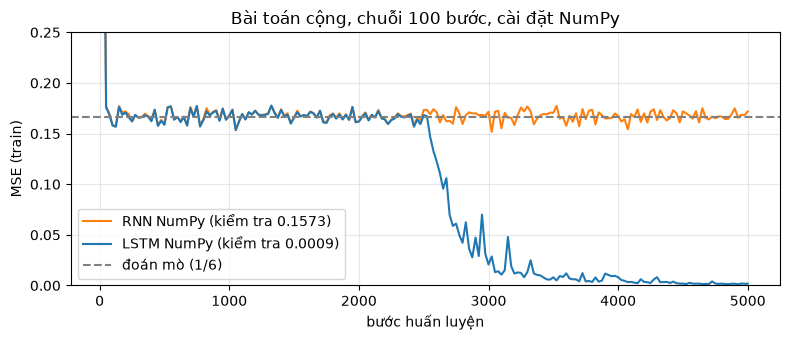

In [9]:
plt.figure(figsize=(8, 3.5))
for name, color in (('rnn', 'tab:orange'), ('lstm', 'tab:blue')):
    c = np.array(runs[name]['curve'])
    plt.plot(c[:, 0], c[:, 1], color=color, label=f"{name.upper()} NumPy (kiểm tra {runs[name]['test_mse']:.4f})")
plt.axhline(1 / 6, color='grey', ls='--', label='đoán mò (1/6)')
plt.ylim(0, 0.25); plt.xlabel('bước huấn luyện'); plt.ylabel('MSE (train)'); plt.grid(alpha=.3); plt.legend()
plt.title('Bài toán cộng, chuỗi 100 bước, cài đặt NumPy')
plt.tight_layout(); plt.savefig(FIGURES / 'numpy_adding_curves.png', bbox_inches='tight'); plt.show()

## 6. Đo tín hiệu lỗi về tới từng bước (số liệu cho slide 18)

Với mỗi mẫu trong tập kiểm tra, đặt đạo hàm ở đầu ra bằng 1 rồi lan truyền ngược, đọc $\left\lVert \partial \hat y / \partial x_t \right\rVert$: dự đoán ở cuối chuỗi **nhạy** thế nào với đầu vào ở bước $t$. Lấy trung bình trên 2000 mẫu, rồi chia cho giá trị ở bước cuối ($t = 100$) để ra **phần trăm tín hiệu còn lại** khi đi ngược $100 - t$ bước.

Đo ở hai thời điểm: lúc mới khởi tạo (chưa học) và sau 5000 bước học. Với LSTM, ghi thêm cổng quên trung bình của **từng** nơ-ron trong 64 nơ-ron ẩn: nơ-ron nào học giữ cổng quên gần 1 là nơ-ron làm "bộ nhớ dài hạn".

In [10]:
def signal_reach(model, params):
    saved, model.p = model.p, params
    model.forward(X_test)
    model.backward(np.ones((len(X_test), 1)))
    reach = np.linalg.norm(model.dX, axis=2).mean(0)          # (T,)
    out = {'reach': (reach / reach[-1]).tolist()}
    if isinstance(model, LSTMNumpy):
        per_unit = model.forget_gates().mean(axis=(0, 1))          # cổng quên trung bình của từng nơ-ron (64 số)
        out['forget_mean'] = float(per_unit.mean())
        out['forget_units'] = np.sort(per_unit)[::-1].tolist()
        out['units_keep'] = int((per_unit > 0.95).sum())         # số nơ-ron gần như luôn GIỮ bộ nhớ
    model.p = saved
    return out

reach = {name: {'before': signal_reach(models[name], before[name]),
                'after': signal_reach(models[name], models[name].p)} for name in models}

for name in reach:
    for when in ('before', 'after'):
        r = reach[name][when]['reach']
        extra = (f"  | cổng quên trung bình {reach[name][when]['forget_mean']:.3f}, "
                 f"{reach[name][when]['units_keep']}/{HIDDEN} nơ-ron có cổng quên > 0.95") if name == 'lstm' else ''
        print(f'{name.upper():4s} {when:6s}: lùi 10 bước còn {100*r[-11]:.3g}%, lùi 50 bước còn {100*r[-51]:.3g}%, lùi 99 bước còn {100*r[0]:.3g}%{extra}')

RNN  before: lùi 10 bước còn 0.951%, lùi 50 bước còn 6.54e-09%, lùi 99 bước còn 8.94e-19%
RNN  after : lùi 10 bước còn 3.25%, lùi 50 bước còn 9.35e-10%, lùi 99 bước còn 3.05e-19%
LSTM before: lùi 10 bước còn 14%, lùi 50 bước còn 0.0533%, lùi 99 bước còn 2.26e-05%  | cổng quên trung bình 0.731, 0/64 nơ-ron có cổng quên > 0.95
LSTM after : lùi 10 bước còn 22.8%, lùi 50 bước còn 22.8%, lùi 99 bước còn 49.5%  | cổng quên trung bình 0.711, 1/64 nơ-ron có cổng quên > 0.95


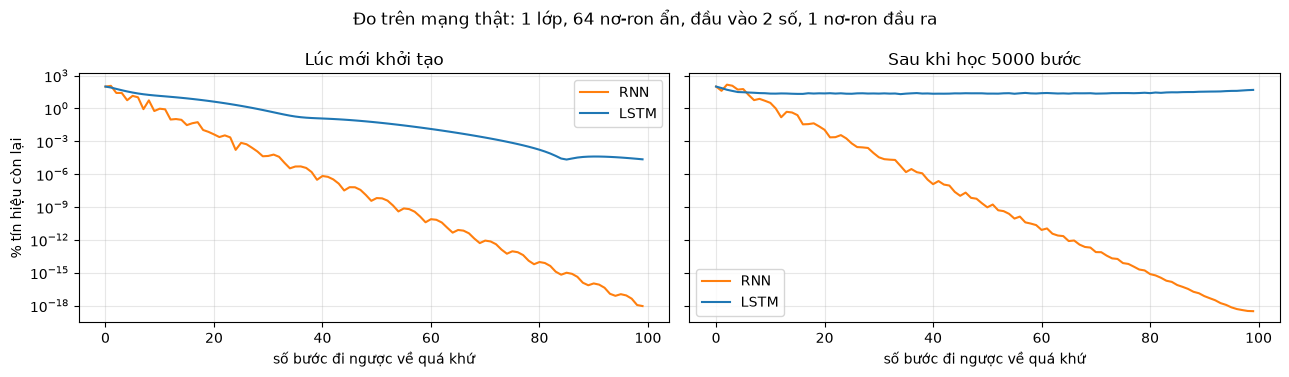

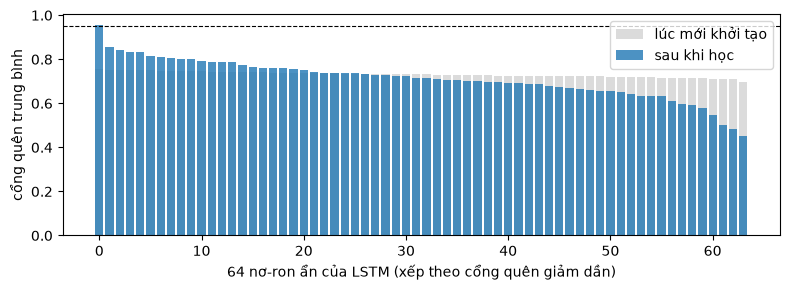

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
back = np.arange(T)[::-1]                                       # số bước đi ngược
for ax, when, title in zip(axes, ('before', 'after'), ('Lúc mới khởi tạo', 'Sau khi học 5000 bước')):
    for name, color in (('rnn', 'tab:orange'), ('lstm', 'tab:blue')):
        ax.semilogy(back, 100 * np.array(reach[name][when]['reach']), color=color, label=name.upper())
    ax.set_title(title); ax.set_xlabel('số bước đi ngược về quá khứ'); ax.grid(alpha=.3, which='both'); ax.legend()
axes[0].set_ylabel('% tín hiệu còn lại')
plt.suptitle('Đo trên mạng thật: 1 lớp, 64 nơ-ron ẩn, đầu vào 2 số, 1 nơ-ron đầu ra')
plt.tight_layout(); plt.savefig(FIGURES / 'numpy_signal_reach.png', bbox_inches='tight'); plt.show()

plt.figure(figsize=(8, 3))
for when, color in (('before', 'lightgray'), ('after', 'tab:blue')):
    plt.bar(np.arange(HIDDEN), reach['lstm'][when]['forget_units'], color=color, alpha=.8,
            label={'before': 'lúc mới khởi tạo', 'after': 'sau khi học'}[when])
plt.axhline(0.95, color='k', ls='--', lw=.8)
plt.xlabel('64 nơ-ron ẩn của LSTM (xếp theo cổng quên giảm dần)'); plt.ylabel('cổng quên trung bình'); plt.legend()
plt.tight_layout(); plt.savefig(FIGURES / 'numpy_forget_units.png', bbox_inches='tight'); plt.show()

## 7. Lưu số liệu

In [12]:
out = {
    'config': {'T': T, 'hidden': HIDDEN, 'layers': 1, 'input': 2, 'output': 1, 'batch': BATCH, 'steps': STEPS,
               'lr': LR, 'clip': 1.0, 'forget_bias': 1.0, 'test_samples': len(X_test),
               'params': {name: m.n_params() for name, m in models.items()}},
    'runs': {name: {**runs[name], **reach[name]} for name in models},
}
(SLIDES_DATA / 'numpy_lstm.json').write_text(json.dumps(out), encoding='utf-8')
(RESULTS / 'lstm_numpy.json').write_text(json.dumps({
    'config': out['config'],
    'test_mse': {n: runs[n]['test_mse'] for n in runs},
    'seconds': {n: runs[n]['seconds'] for n in runs},
    'reach_at': {n: {w: {str(k): reach[n][w]['reach'][T - 1 - k] for k in (10, 50, 99)} for w in ('before', 'after')} for n in reach},
    'forget_mean': {w: reach['lstm'][w]['forget_mean'] for w in ('before', 'after')},
    'units_keep': {w: reach['lstm'][w]['units_keep'] for w in ('before', 'after')},
}, indent=1), encoding='utf-8')
print('Đã lưu', SLIDES_DATA / 'numpy_lstm.json', 'và', RESULTS / 'lstm_numpy.json')

Đã lưu ../slides/data/numpy_lstm.json và results/lstm_numpy.json
